# Hunting Exoplanets — an End-to-End Machine Learning Project

This notebook contains all the code of the guide `index.html` (same folder).
Every figure of the guide is produced here and saved in `images/`.

**Data (real):** NASA Kepler light curves of the star Kepler-90 (MAST archive) and the
NASA Exoplanet Archive table of all 9,564 Kepler Objects of Interest (KOIs).

## Setup

In [1]:
# Python ≥3.8 is required
import sys
assert sys.version_info >= (3, 8)

# Scikit-Learn ≥1.0 is required
import sklearn
assert sklearn.__version__ >= "1.0"

# Common imports
import os
import numpy as np
import pandas as pd

# To make this notebook's output stable across runs
np.random.seed(42)

# To plot pretty figures
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('axes', labelsize=13)
mpl.rc('xtick', labelsize=11)
mpl.rc('ytick', labelsize=11)

# Where to save the figures
PROJECT_ROOT_DIR = "."
IMAGES_PATH = os.path.join(PROJECT_ROOT_DIR, "images")
os.makedirs(IMAGES_PATH, exist_ok=True)

def save_fig(fig_id, tight_layout=True, fig_extension="png", resolution=150):
    path = os.path.join(IMAGES_PATH, fig_id + "." + fig_extension)
    print("Saving figure", fig_id)
    if tight_layout:
        plt.tight_layout()
    plt.savefig(path, format=fig_extension, dpi=resolution)

## Get the Data

In [2]:
DATASETS_PATH = "datasets"
KEPLER90_KIC = 11442793

def fetch_kepler_light_curve(kic=KEPLER90_KIC, path=os.path.join(DATASETS_PATH, "kepler")):
    """Download every long-cadence quarter from NASA's MAST archive (needs astroquery
    and astropy the first time), keep the useful columns, cache them as one CSV."""
    os.makedirs(path, exist_ok=True)
    csv_path = os.path.join(path, f"kplr{kic:09d}_llc.csv")
    if os.path.exists(csv_path):
        return pd.read_csv(csv_path)
    from astroquery.mast import Observations
    from astropy.io import fits
    obs = Observations.query_criteria(target_name=f"kplr{kic:09d}", obs_collection="Kepler")
    products = Observations.get_product_list(obs)
    llc = products[[str(f).endswith("_llc.fits") for f in products["productFilename"]]]
    manifest = Observations.download_products(llc, download_dir=path)
    frames = []
    for fname in sorted(manifest["Local Path"]):
        with fits.open(fname) as hdul:
            d, quarter = hdul[1].data, hdul[0].header["QUARTER"]
            frames.append(pd.DataFrame({"time": d["TIME"], "sap_flux": d["SAP_FLUX"],
                                        "pdcsap_flux": d["PDCSAP_FLUX"],
                                        "pdcsap_flux_err": d["PDCSAP_FLUX_ERR"],
                                        "quality": d["SAP_QUALITY"], "quarter": quarter}))
    lc = pd.concat(frames, ignore_index=True)
    lc.to_csv(csv_path, index=False)
    for fname in manifest["Local Path"]:          # the CSV is all we need from now on
        os.remove(fname)
    return lc

lc = fetch_kepler_light_curve()
lc.head()

,time,sap_flux,pdcsap_flux,pdcsap_flux_err,quality,quarter
0,131.512439,34751.586,39024.062,6.886208,0,1
1,131.532874,34765.273,39034.062,6.890465,0,1
2,131.553308,34759.652,39028.047,6.890853,8192,1
3,131.573742,34753.820,39028.258,6.882296,0,1
4,131.594176,34762.880,39031.824,6.889281,0,1


In [3]:
import urllib.parse
import urllib.request

KOI_COLUMNS = ["kepid", "kepoi_name", "kepler_name", "koi_disposition", "koi_score",
               "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec",
               "koi_period", "koi_time0bk", "koi_duration", "koi_depth", "koi_prad",
               "koi_impact", "koi_model_snr", "koi_num_transits", "koi_teq", "koi_insol",
               "koi_steff", "koi_slogg", "koi_srad", "koi_smass", "koi_kepmag"]

def fetch_koi_table(path=os.path.join(DATASETS_PATH, "nasa")):
    os.makedirs(path, exist_ok=True)
    csv_path = os.path.join(path, "kepler_koi_cumulative.csv")
    if not os.path.exists(csv_path):
        query = f"select {','.join(KOI_COLUMNS)} from cumulative"
        url = ("https://exoplanetarchive.ipac.caltech.edu/TAP/sync?" +
               urllib.parse.urlencode({"query": query, "format": "csv"}))
        urllib.request.urlretrieve(url, csv_path)
    return pd.read_csv(csv_path)

koi = fetch_koi_table()
koi.shape

(9564, 24)

## Take a Quick Look at the Data Structure

In [4]:
lc.info()

<class 'pandas.DataFrame'>
RangeIndex: 54400 entries, 0 to 54399
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   time             52553 non-null  float64
 1   sap_flux         51759 non-null  float64
 2   pdcsap_flux      51503 non-null  float64
 3   pdcsap_flux_err  51503 non-null  float64
 4   quality          54400 non-null  int64  
 5   quarter          54400 non-null  int64  
dtypes: float64(4), int64(2)
memory usage: 2.5 MB


In [5]:
lc.groupby("quarter").agg(points=("time", "size"), start=("time", "min"), end=("time", "max")).T.round(1)

quarter,1,2,3,4,5,6,7,9,10,11,13,14,15,17
points,1639.0,4354.0,4370.0,1021.0,4634.0,4398.0,4375.0,4768.0,4573.0,4754.0,4421.0,4757.0,4780.0,1556.0
start,131.5,169.5,260.2,352.4,443.5,539.4,630.2,808.5,906.8,1001.2,1182.7,1274.1,1373.5,1559.2
end,165.0,258.5,349.5,373.2,538.2,629.3,719.5,905.9,1000.3,1098.3,1273.1,1371.3,1471.1,1591.0


Saving figure raw_light_curve_plot


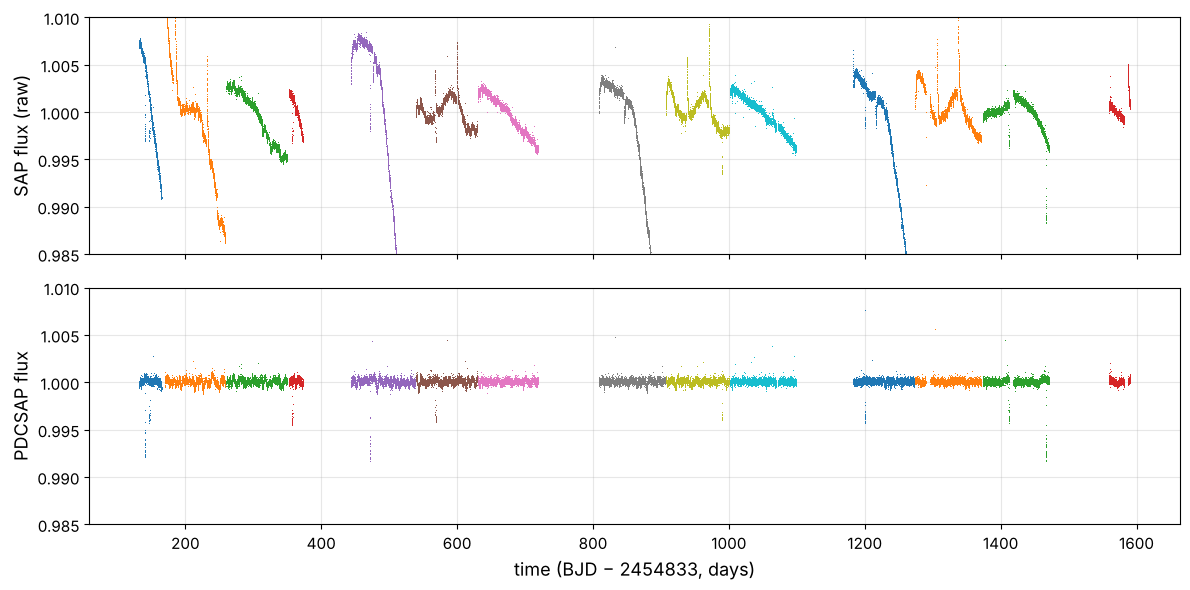

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for q, grp in lc.groupby("quarter"):
    axes[0].plot(grp["time"], grp["sap_flux"] / grp["sap_flux"].median(), ",")
    axes[1].plot(grp["time"], grp["pdcsap_flux"] / grp["pdcsap_flux"].median(), ",")
axes[0].set_ylabel("SAP flux (raw)"); axes[1].set_ylabel("PDCSAP flux")
axes[1].set_xlabel("time (BJD − 2454833, days)")
for ax in axes: ax.set_ylim(0.985, 1.01); ax.grid(alpha=0.3)
save_fig("raw_light_curve_plot")
plt.show()

In [7]:
koi.info()

<class 'pandas.DataFrame'>
RangeIndex: 9564 entries, 0 to 9563
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   kepid             9564 non-null   int64  
 1   kepoi_name        9564 non-null   str    
 2   kepler_name       2748 non-null   str    
 3   koi_disposition   9564 non-null   str    
 4   koi_score         8054 non-null   float64
 5   koi_fpflag_nt     9564 non-null   int64  
 6   koi_fpflag_ss     9564 non-null   int64  
 7   koi_fpflag_co     9564 non-null   int64  
 8   koi_fpflag_ec     9564 non-null   int64  
 9   koi_period        9564 non-null   float64
 10  koi_time0bk       9564 non-null   float64
 11  koi_duration      9564 non-null   float64
 12  koi_depth         9201 non-null   float64
 13  koi_prad          9201 non-null   float64
 14  koi_impact        9201 non-null   float64
 15  koi_model_snr     9201 non-null   float64
 16  koi_num_transits  8422 non-null   float64
 17  koi_te

In [8]:
koi["koi_disposition"].value_counts()

koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
CANDIDATE         1977
Name: count, dtype: int64

In [9]:
koi[["koi_period", "koi_duration", "koi_depth", "koi_prad", "koi_model_snr", "koi_steff",
     "koi_srad"]].describe().round(2)

,koi_period,koi_duration,koi_depth,koi_prad,koi_model_snr,koi_steff,koi_srad
count,9564.00,9564.00,9201.00,9201.00,9201.00,9201.00,9201.00
mean,75.67,5.62,23791.34,102.89,259.90,5706.82,1.73
std,1334.74,6.47,82242.68,3077.64,795.81,796.86,6.13
min,0.24,0.05,0.00,0.08,0.00,2661.00,0.11
25%,2.73,2.44,159.90,1.40,12.00,5310.00,0.83
50%,9.75,3.79,421.10,2.39,23.00,5767.00,1.00
75%,40.72,6.28,1473.40,14.93,78.00,6112.00,1.34
max,129995.78,138.54,1541400.00,200346.00,9054.70,15896.00,229.91


Saving figure koi_histogram_plots


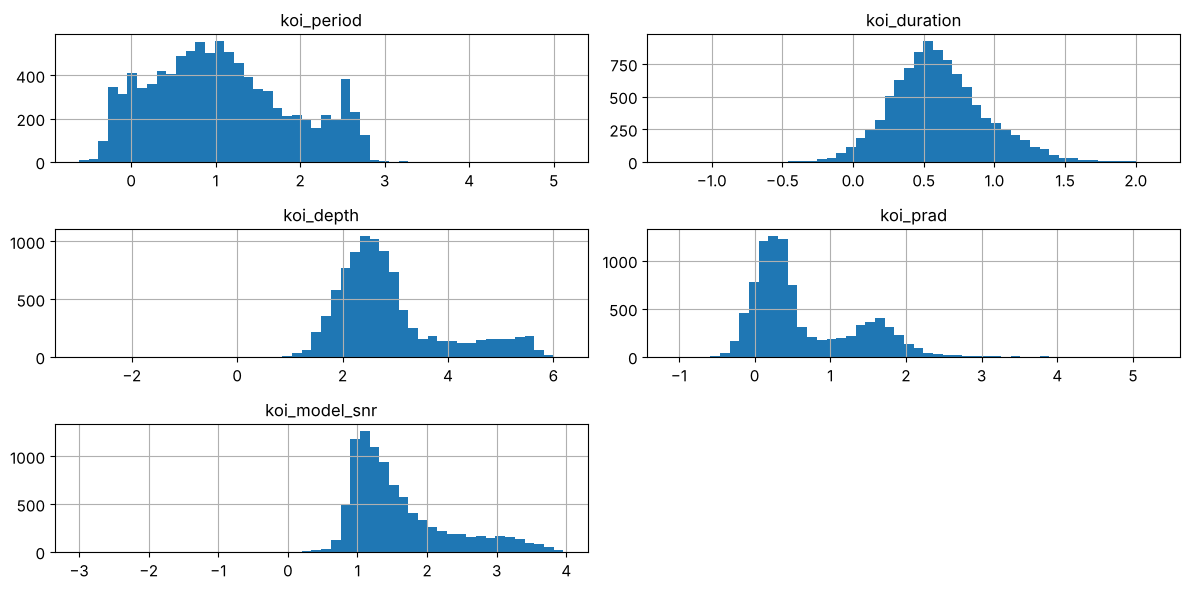

In [10]:
np.log10(koi[["koi_period", "koi_duration", "koi_depth", "koi_prad", "koi_model_snr"]]
         .clip(lower=1e-3)).hist(bins=50, figsize=(12, 6))
save_fig("koi_histogram_plots")
plt.show()

## Create a Test Set

In [11]:
from sklearn.model_selection import StratifiedGroupKFold

labeled = koi[koi["koi_disposition"].isin(["CONFIRMED", "FALSE POSITIVE"])].copy()
labeled["is_planet"] = (labeled["koi_disposition"] == "CONFIRMED").astype(int)
# Kepler-90 is our final, independent test: keep all of its KOIs out of everything
holdout_star = labeled["kepid"] == KEPLER90_KIC
labeled = labeled[~holdout_star]
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(splitter.split(labeled, labeled["is_planet"], groups=labeled["kepid"]))
train_set, test_set = labeled.iloc[train_idx].copy(), labeled.iloc[test_idx].copy()
print(len(train_set), "train,", len(test_set), "test, shared stars:",
      len(set(train_set["kepid"]) & set(test_set["kepid"])))
print("planet fraction: train %.3f, test %.3f" % (train_set["is_planet"].mean(), test_set["is_planet"].mean()))

6064 train, 1516 test, shared stars: 0
planet fraction: train 0.362, test 0.361


## Discover and Visualize the Data to Gain Insights

In [12]:
from scipy.ndimage import median_filter

good = (lc["quality"] == 0) & lc["time"].notna() & lc["pdcsap_flux"].notna()
lc_good = lc[good].copy()
lc_good["flux"] = lc_good["pdcsap_flux"] / lc_good.groupby("quarter")["pdcsap_flux"].transform("median")
len(lc), len(lc_good)

(54400, 44744)

Saving figure light_curve_zoom_plot


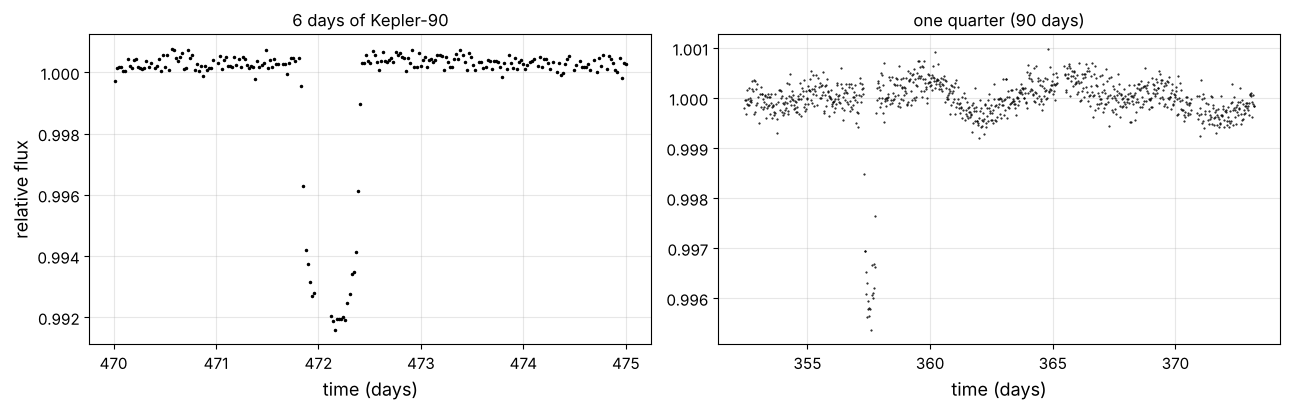

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
win = (lc_good["time"] > 470) & (lc_good["time"] < 476)
axes[0].plot(lc_good.loc[win, "time"], lc_good.loc[win, "flux"], "k.", ms=3)
axes[0].set_title("6 days of Kepler-90"); axes[0].set_xlabel("time (days)"); axes[0].set_ylabel("relative flux")
q = lc_good["quarter"] == 4
axes[1].plot(lc_good.loc[q, "time"], lc_good.loc[q, "flux"], "k.", ms=1)
axes[1].set_title("one quarter (90 days)"); axes[1].set_xlabel("time (days)")
for ax in axes: ax.grid(alpha=0.3)
save_fig("light_curve_zoom_plot")
plt.show()

Saving figure period_radius_plot


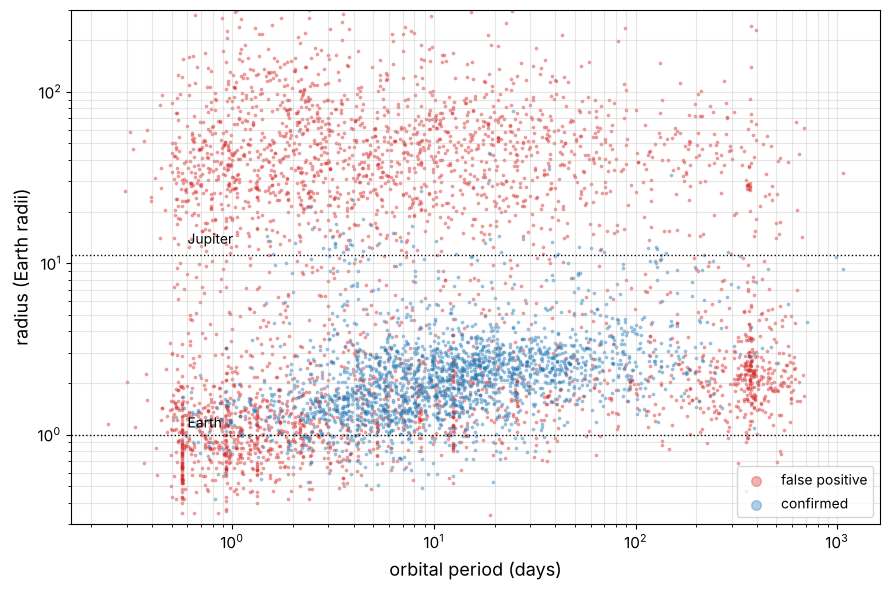

In [14]:
fig, ax = plt.subplots(figsize=(9, 6))
for label, color in [("FALSE POSITIVE", "tab:red"), ("CONFIRMED", "tab:blue")]:
    s = train_set[train_set["koi_disposition"] == label]
    ax.scatter(s["koi_period"], s["koi_prad"], s=3, alpha=0.35, color=color, label=label.lower())
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(0.3, 300)
ax.axhline(11.2, color="k", ls=":", lw=1); ax.text(0.6, 13, "Jupiter", fontsize=10)
ax.axhline(1.0, color="k", ls=":", lw=1); ax.text(0.6, 1.1, "Earth", fontsize=10)
ax.set_xlabel("orbital period (days)"); ax.set_ylabel("radius (Earth radii)")
ax.legend(markerscale=4); ax.grid(alpha=0.3, which="both")
save_fig("period_radius_plot")
plt.show()

In [15]:
num = train_set[["is_planet", "koi_period", "koi_duration", "koi_depth", "koi_prad",
                 "koi_model_snr", "koi_steff", "koi_slogg", "koi_srad", "koi_kepmag"]]
np.log10(num.drop(columns="is_planet").clip(lower=1e-3)).assign(is_planet=num["is_planet"]) \
    .corr()["is_planet"].sort_values(ascending=False).round(3)

is_planet        1.000
koi_slogg        0.151
koi_period       0.101
koi_kepmag       0.063
koi_duration    -0.133
koi_model_snr   -0.181
koi_srad        -0.197
koi_steff       -0.222
koi_depth       -0.241
koi_prad        -0.398
Name: is_planet, dtype: float64

In [16]:
# Kepler's third law predicts how long a transit should last around a star of given
# density: T ≈ 13 h × (P / 1 yr)^(1/3) × (ρ★/ρ☉)^(-1/3)  (central transit, circular orbit)
def expected_duration_hours(period_days, logg, srad):
    rho = 10 ** (logg - 4.438) / srad                   # stellar density (solar units)
    return 13.0 * (period_days / 365.25) ** (1 / 3) * rho ** (-1 / 3)

train_set["duration_ratio"] = train_set["koi_duration"] / expected_duration_hours(
    train_set["koi_period"], train_set["koi_slogg"], train_set["koi_srad"])
train_set.groupby("koi_disposition")["duration_ratio"].describe()[["25%", "50%", "75%"]].round(2)

,25%,50%,75%
koi_disposition,,,
CONFIRMED,0.73,0.90,1.03
FALSE POSITIVE,0.63,1.09,1.74


Saving figure duration_ratio_plot


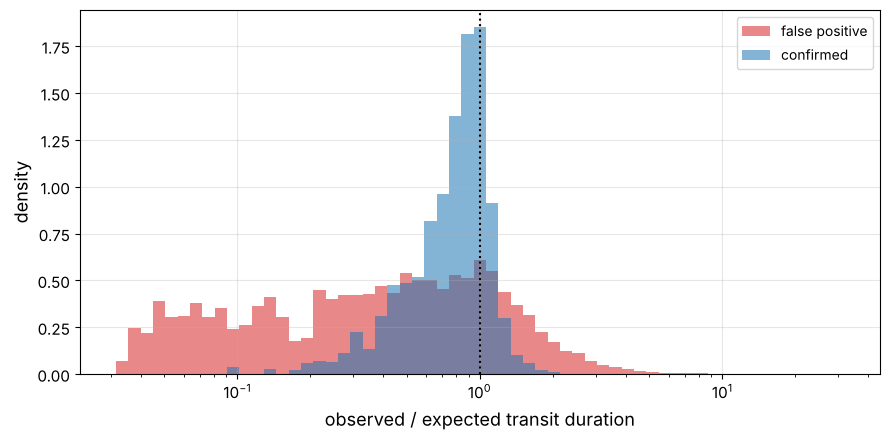

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bins = np.logspace(-1.5, 1.5, 60)
for label, color in [("FALSE POSITIVE", "tab:red"), ("CONFIRMED", "tab:blue")]:
    ax.hist(train_set.loc[train_set["koi_disposition"] == label, "duration_ratio"], bins=bins,
            alpha=0.55, color=color, label=label.lower(), density=True)
ax.set_xscale("log"); ax.set_xlabel("observed / expected transit duration"); ax.set_ylabel("density")
ax.axvline(1, color="k", ls=":"); ax.legend(); ax.grid(alpha=0.3)
save_fig("duration_ratio_plot")
plt.show()

## Prepare the Data for Machine Learning Algorithms

In [18]:
from sklearn.base import BaseEstimator, TransformerMixin

class LightCurveDetrender(BaseEstimator, TransformerMixin):
    """Divide each quarter by a running median (removes stellar and instrumental drifts
    slower than the window), then clip upward outliers (cosmic rays, flares)."""
    def __init__(self, window_days=1.0, clip_sigma=4.0):
        self.window_days = window_days
        self.clip_sigma = clip_sigma
    def fit(self, X, y=None):
        return self
    def __sklearn_is_fitted__(self):
        return True
    def transform(self, X):
        out = []
        for q, grp in X.groupby("quarter"):
            size = int(self.window_days / (29.4244 / 1440)) | 1      # odd number of cadences
            trend = median_filter(grp["flux"].values, size=size, mode="nearest")
            out.append(pd.DataFrame({"time": grp["time"].values, "flux": grp["flux"].values / trend}))
        out = pd.concat(out, ignore_index=True)
        noise = 1.4826 * np.median(np.abs(out["flux"] - 1))
        return out[out["flux"] < 1 + self.clip_sigma * noise].reset_index(drop=True)

detrended = LightCurveDetrender().fit_transform(lc_good)
noise_ppm = 1e6 * 1.4826 * np.median(np.abs(detrended["flux"] - 1))
print(f"{len(detrended)} points, robust noise = {noise_ppm:.0f} ppm per 29.4-minute cadence")

44720 points, robust noise = 178 ppm per 29.4-minute cadence


Saving figure detrended_light_curve_plot


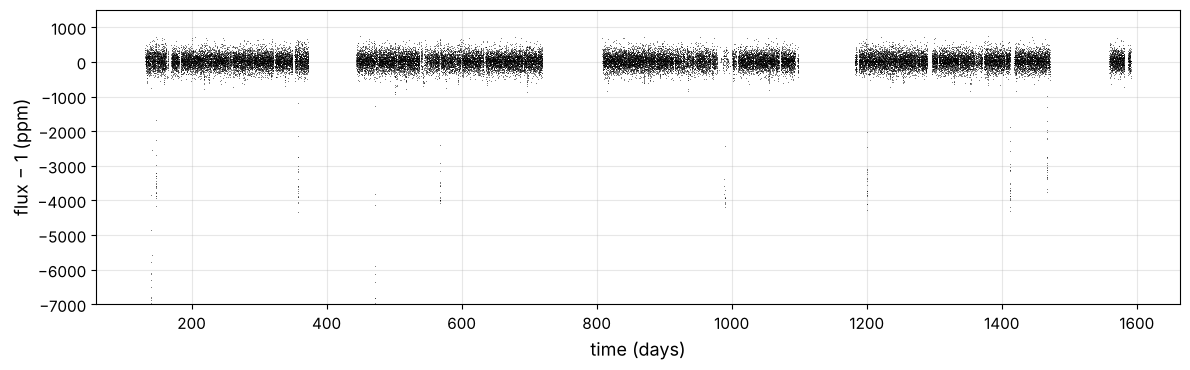

In [19]:
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(detrended["time"], (detrended["flux"] - 1) * 1e6, "k,", alpha=0.5)
ax.set_ylim(-7000, 1500); ax.set_xlabel("time (days)"); ax.set_ylabel("flux − 1 (ppm)")
ax.grid(alpha=0.3)
save_fig("detrended_light_curve_plot")
plt.show()

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler

TRANSIT_FEATURES = ["koi_period", "koi_duration", "koi_depth", "koi_prad", "koi_model_snr"]
STAR_FEATURES = ["koi_steff", "koi_slogg", "koi_srad", "koi_kepmag"]

class DurationRatioAdder(BaseEstimator, TransformerMixin):
    """Adds observed/expected transit duration (an engineered physics feature)."""
    def __init__(self, add_duration_ratio=True):
        self.add_duration_ratio = add_duration_ratio
    def fit(self, X, y=None):
        return self
    def __sklearn_is_fitted__(self):
        return True
    def transform(self, X):
        X = X.copy()
        if self.add_duration_ratio:
            X["duration_ratio"] = X["koi_duration"] / expected_duration_hours(
                X["koi_period"], X["koi_slogg"], X["koi_srad"])
        return X

log_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(lambda x: np.log10(np.clip(x, 1e-3, None)), feature_names_out="one-to-one")),
    ("scaler", StandardScaler()),
])
star_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
def make_preprocessing(add_duration_ratio=True):
    cols_log = TRANSIT_FEATURES + (["duration_ratio"] if add_duration_ratio else [])
    return Pipeline([
        ("attribs", DurationRatioAdder(add_duration_ratio)),
        ("columns", ColumnTransformer([("transit", log_pipeline, cols_log),
                                       ("star", star_pipeline, STAR_FEATURES)])),
    ])

preprocessing = make_preprocessing()
X_train = train_set[TRANSIT_FEATURES + STAR_FEATURES]
y_train = train_set["is_planet"].values
X_train_prepared = preprocessing.fit_transform(X_train)
X_train_prepared.shape

(6064, 10)

## Select and Train a Model

In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, GroupKFold

groups = train_set["kepid"].values
leaky = train_set[TRANSIT_FEATURES + STAR_FEATURES + ["koi_score", "koi_fpflag_nt", "koi_fpflag_ss",
                                                      "koi_fpflag_co", "koi_fpflag_ec"]].fillna(-1)
scores = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=42), leaky, y_train,
                         groups=groups, cv=GroupKFold(5), scoring="accuracy")
print(f"accuracy WITH the vetting flags: {scores.mean():.4f}   <- too good to be true")

accuracy WITH the vetting flags: 0.9941   <- too good to be true


In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

log_clf = Pipeline([("prep", make_preprocessing()), ("clf", LogisticRegression(max_iter=1000))])
log_clf.fit(X_train, y_train)
print("training ROC AUC:", round(roc_auc_score(y_train, log_clf.predict_proba(X_train)[:, 1]), 4))

training ROC AUC: 0.8531


In [23]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_validate

def display_scores(name, s):
    print(f"{name:26s} AUC {s['test_roc_auc'].mean():.4f} ± {s['test_roc_auc'].std():.4f}   "
          f"accuracy {s['test_accuracy'].mean():.4f}")

candidates = {
    "logistic regression": LogisticRegression(max_iter=1000),
    "random forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "gradient boosting": HistGradientBoostingClassifier(random_state=42),
}
cv = GroupKFold(5)
for name, clf in candidates.items():
    for ratio in (False, True):
        model = Pipeline([("prep", make_preprocessing(ratio)), ("clf", clf)])
        s = cross_validate(model, X_train, y_train, groups=groups, cv=cv, scoring=["roc_auc", "accuracy"])
        display_scores(name + (" + duration ratio" if ratio else ""), s)

logistic regression        AUC 0.8300 ± 0.0106   accuracy 0.7536


logistic regression + duration ratio AUC 0.8515 ± 0.0099   accuracy 0.7688


random forest              AUC 0.9701 ± 0.0038   accuracy 0.9197


random forest + duration ratio AUC 0.9736 ± 0.0014   accuracy 0.9256


gradient boosting          AUC 0.9749 ± 0.0028   accuracy 0.9241


gradient boosting + duration ratio AUC 0.9761 ± 0.0011   accuracy 0.9288


## Fine-Tune Your Model

In [24]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, loguniform

full_pipeline = Pipeline([("prep", make_preprocessing()), ("clf", HistGradientBoostingClassifier(random_state=42))])
param_distribs = {"clf__learning_rate": loguniform(0.02, 0.3),
                  "clf__max_leaf_nodes": randint(8, 64),
                  "clf__min_samples_leaf": randint(10, 80),
                  "clf__l2_regularization": loguniform(1e-3, 10)}
rnd_search = RandomizedSearchCV(full_pipeline, param_distribs, n_iter=25, cv=cv, scoring="roc_auc",
                                random_state=42, n_jobs=-1)
rnd_search.fit(X_train, y_train, groups=groups)
print("best CV AUC:", round(rnd_search.best_score_, 4))
rnd_search.best_params_

best CV AUC: 0.9766


{'clf__l2_regularization': np.float64(0.24400607090817547),
 'clf__learning_rate': np.float64(0.06689135590392836),
 'clf__max_leaf_nodes': 30,
 'clf__min_samples_leaf': 33}

In [25]:
from sklearn.inspection import permutation_importance

final_model = rnd_search.best_estimator_
imp = permutation_importance(final_model, X_train, y_train, scoring="roc_auc", n_repeats=5, random_state=42)
pd.Series(imp.importances_mean, index=X_train.columns).sort_values(ascending=False).round(4)

koi_prad         0.1766
koi_period       0.1541
koi_duration     0.0963
koi_model_snr    0.0480
koi_steff        0.0220
koi_srad         0.0135
koi_depth        0.0079
koi_slogg        0.0074
koi_kepmag       0.0022
dtype: float64

## Evaluate Your System on the Test Set

In [26]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, roc_curve

X_test, y_test = test_set[TRANSIT_FEATURES + STAR_FEATURES], test_set["is_planet"].values
p_test = final_model.predict_proba(X_test)[:, 1]
print("test ROC AUC:", round(roc_auc_score(y_test, p_test), 4))
y_pred = (p_test >= 0.5).astype(int)
print("precision:", round(precision_score(y_test, y_pred), 3), " recall:", round(recall_score(y_test, y_pred), 3))
confusion_matrix(y_test, y_pred)

test ROC AUC: 0.9693
precision: 0.874  recall: 0.896


array([[897,  71],
       [ 57, 491]])

Saving figure roc_precision_recall_plot


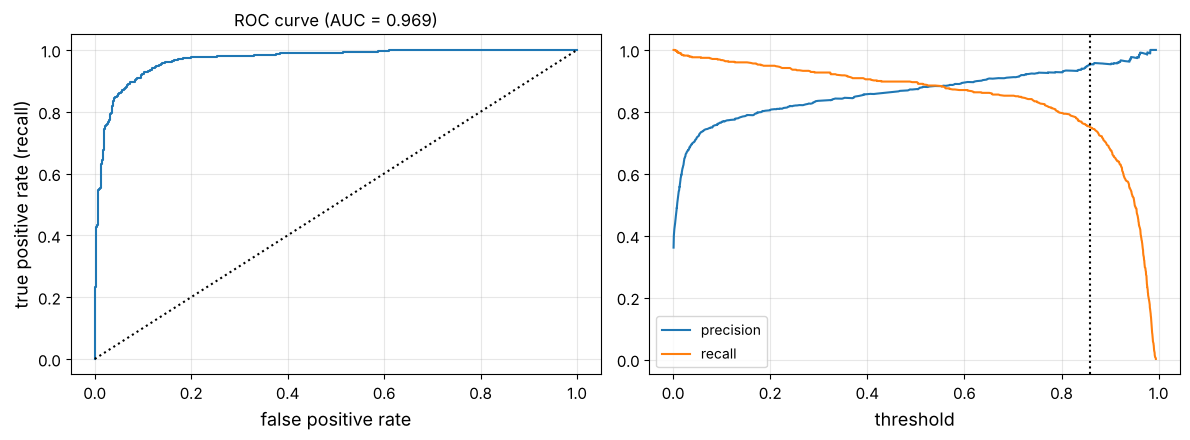

threshold for 95% precision: 0.86 -> recall 0.75


In [27]:
from sklearn.metrics import precision_recall_curve
prec, rec, thr = precision_recall_curve(y_test, p_test)
i95 = np.argmax(prec[:-1] >= 0.95)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
fpr, tpr, _ = roc_curve(y_test, p_test)
axes[0].plot(fpr, tpr); axes[0].plot([0, 1], [0, 1], "k:")
axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("true positive rate (recall)")
axes[0].set_title(f"ROC curve (AUC = {roc_auc_score(y_test, p_test):.3f})")
axes[1].plot(thr, prec[:-1], label="precision"); axes[1].plot(thr, rec[:-1], label="recall")
axes[1].axvline(thr[i95], color="k", ls=":"); axes[1].set_xlabel("threshold"); axes[1].legend()
for ax in axes: ax.grid(alpha=0.3)
save_fig("roc_precision_recall_plot")
plt.show()
print(f"threshold for 95% precision: {thr[i95]:.2f} -> recall {rec[i95]:.2f}")

## Launch: Hunt for Planets Around Kepler-90

In [28]:
from astropy.timeseries import BoxLeastSquares

def search_transits(lc, n_signals=9, min_period=1.0, max_period=400.0, n_periods=20000,
                    durations=(0.08, 0.12, 0.2, 0.3, 0.45, 0.6), mask_factor=1.5):
    """Box Least Squares search: find the strongest periodic dip, record it, mask its
    transits, search again (iterative 'peeling')."""
    t, f = lc["time"].values, lc["flux"].values
    periods = np.exp(np.linspace(np.log(min_period), np.log(max_period), n_periods))
    keep = np.ones(len(t), bool)
    noise = 1.4826 * np.median(np.abs(f - 1))
    found, spectra = [], []
    for k in range(n_signals):
        bls = BoxLeastSquares(t[keep], f[keep])
        res = bls.power(periods, list(durations), objective="likelihood")
        i = np.argmax(res.power)
        P, t0, dur, depth = res.period[i], res.transit_time[i], res.duration[i], res.depth[i]
        phase = ((t - t0 + 0.5 * P) % P) - 0.5 * P
        in_transit = keep & (np.abs(phase) < dur / 2)
        epochs = np.unique(np.round((t[in_transit] - t0) / P))
        found.append({"period": P, "t0": t0, "duration_h": dur * 24, "depth_ppm": depth * 1e6,
                      "snr": depth / noise * np.sqrt(in_transit.sum()), "n_transits": len(epochs)})
        spectra.append(res.power)
        keep &= np.abs(phase) > mask_factor * dur
    return pd.DataFrame(found), periods, spectra

signals, periods, spectra = search_transits(detrended)
signals.round(3)

,period,t0,duration_h,depth_ppm,snr,n_transits
0,331.598,140.488,10.752,5632.421,234.645,3
1,210.618,147.008,10.752,2769.404,160.921,6
2,311.939,163.992,10.752,3561.066,93.827,1
3,59.739,158.944,7.296,408.176,33.068,15
4,91.935,134.352,7.296,349.443,24.984,12
5,124.906,254.728,7.296,363.845,14.739,6
6,7.008,137.700,2.880,90.890,14.332,150
7,8.721,139.460,4.800,70.812,12.072,113
8,264.234,279.048,7.296,470.467,8.357,2


Saving figure bls_periodograms_plot


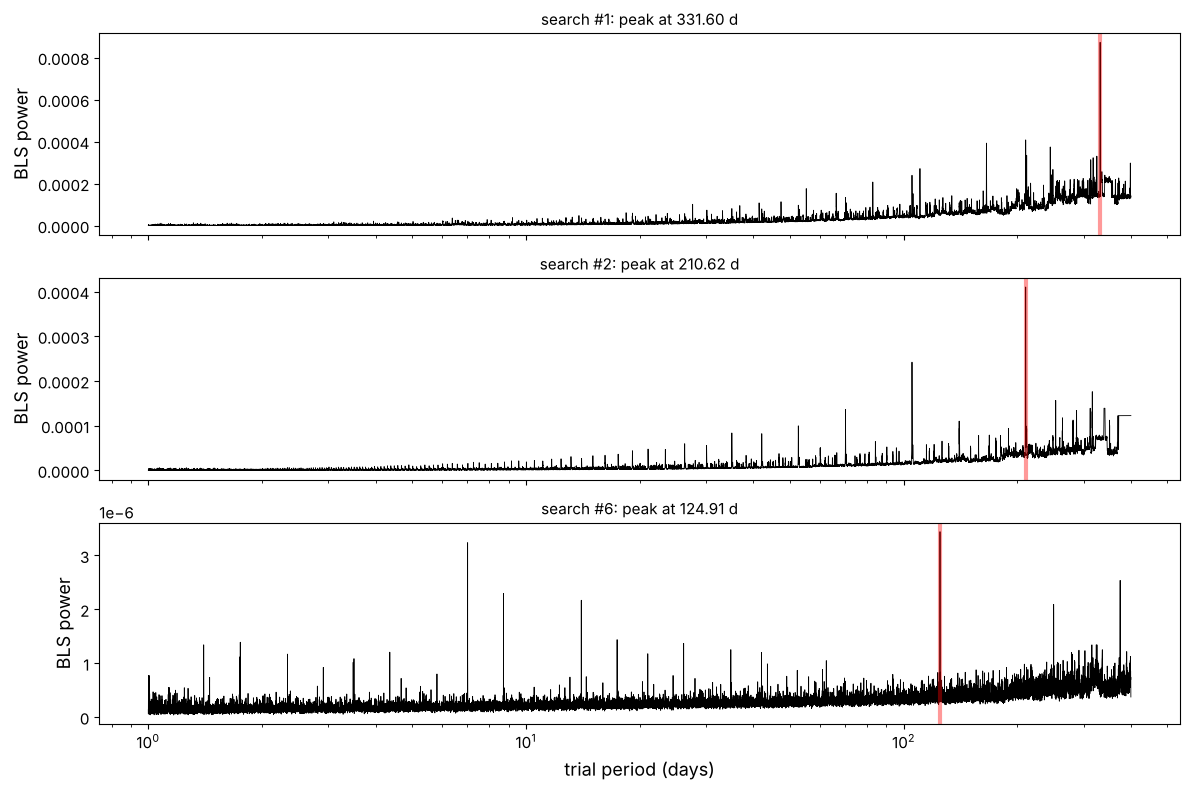

In [29]:
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, k in zip(axes, (0, 1, 5)):
    ax.plot(periods, spectra[k], "k-", lw=0.6)
    ax.axvline(signals.loc[k, "period"], color="r", alpha=0.4, lw=3)
    ax.set_ylabel("BLS power"); ax.set_title(f"search #{k + 1}: peak at {signals.loc[k, 'period']:.2f} d", fontsize=11)
axes[-1].set_xscale("log"); axes[-1].set_xlabel("trial period (days)")
save_fig("bls_periodograms_plot")
plt.show()

Saving figure folded_transits_plot


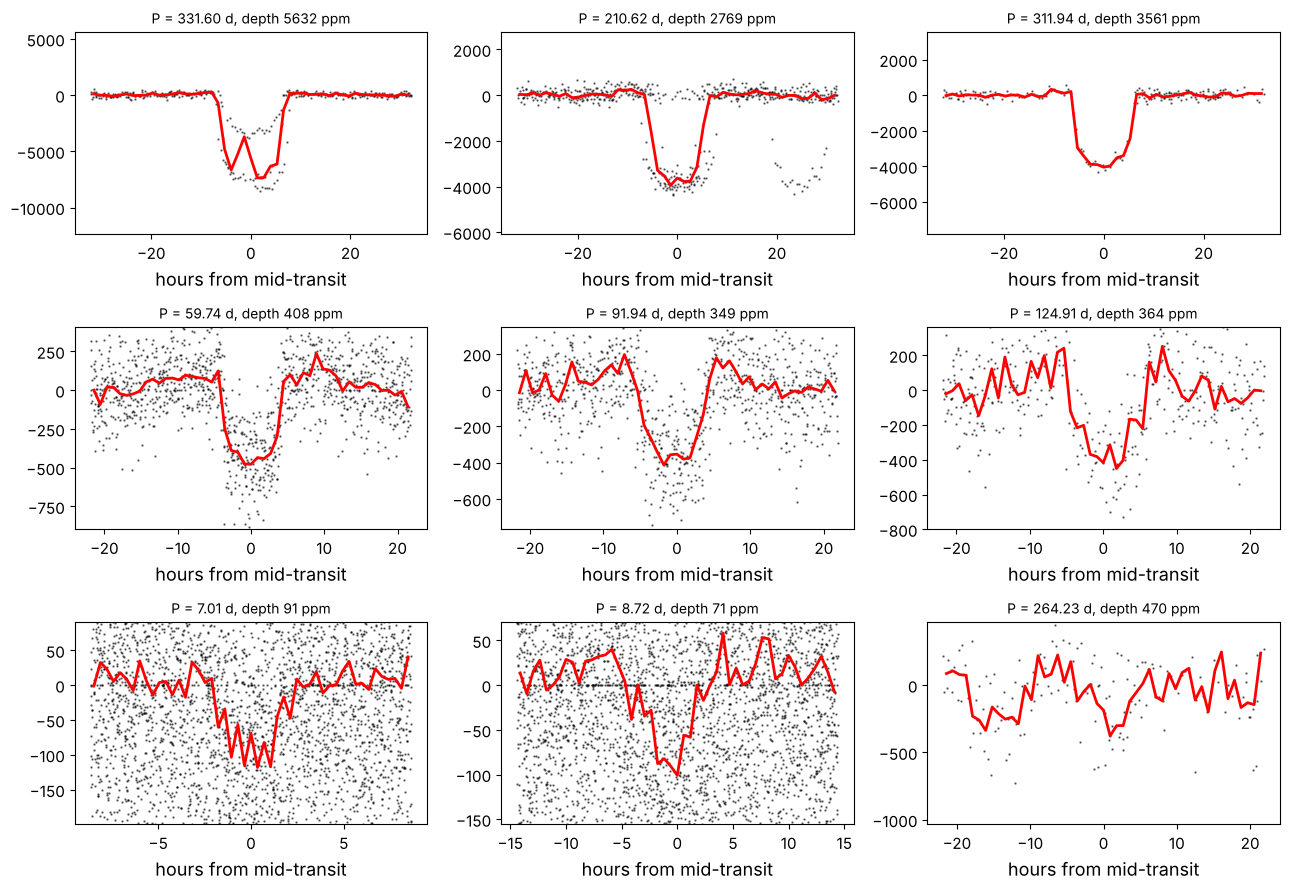

In [30]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, (k, row) in zip(axes.ravel(), signals.iterrows()):
    P, t0 = row["period"], row["t0"]
    ph = (((detrended["time"] - t0 + 0.5 * P) % P) - 0.5 * P) * 24
    sel = np.abs(ph) < 3 * row["duration_h"]
    ax.plot(ph[sel], (detrended["flux"][sel] - 1) * 1e6, "k.", ms=1.5, alpha=0.5)
    bins = np.linspace(-3 * row["duration_h"], 3 * row["duration_h"], 50)
    which = np.digitize(ph[sel], bins)
    med = [np.median(detrended["flux"][sel][which == j]) for j in range(1, len(bins))]
    ax.plot(0.5 * (bins[1:] + bins[:-1]), (np.array(med) - 1) * 1e6, "r-", lw=2)
    ax.set_ylim(-2.2 * row["depth_ppm"], 1.0 * row["depth_ppm"])
    ax.set_title(f"P = {P:.2f} d, depth {row['depth_ppm']:.0f} ppm", fontsize=10)
    ax.set_xlabel("hours from mid-transit")
save_fig("folded_transits_plot")
plt.show()

In [31]:
known = koi[koi["kepid"] == KEPLER90_KIC][["kepoi_name", "kepler_name", "koi_period", "koi_depth",
                                          "koi_duration", "koi_model_snr", "koi_prad"]]
def match(P):
    rel = np.abs(known["koi_period"] / P - 1)
    return known.iloc[rel.argmin()]["kepler_name"] if rel.min() < 0.002 else "—"
signals["matches"] = signals["period"].map(match)
signals[["period", "depth_ppm", "duration_h", "snr", "n_transits", "matches"]].round(2)

,period,depth_ppm,duration_h,snr,n_transits,matches
0,331.60,5632.42,10.75,234.65,3,Kepler-90 h
1,210.62,2769.40,10.75,160.92,6,Kepler-90 g
2,311.94,3561.07,10.75,93.83,1,—
3,59.74,408.18,7.30,33.07,15,Kepler-90 d
4,91.94,349.44,7.30,24.98,12,Kepler-90 e
5,124.91,363.85,7.30,14.74,6,Kepler-90 f
6,7.01,90.89,2.88,14.33,150,Kepler-90 b
7,8.72,70.81,4.80,12.07,113,Kepler-90 c
8,264.23,470.47,7.30,8.36,2,—


In [32]:
# Do our features look like the catalogue's? (training/serving skew check)
both = signals[signals["matches"] != "—"].merge(known, left_on="matches", right_on="kepler_name")
both[["matches", "period", "koi_period", "depth_ppm", "koi_depth", "duration_h", "koi_duration",
      "snr", "koi_model_snr"]].round(1)

,matches,period,koi_period,depth_ppm,koi_depth,duration_h,koi_duration,snr,koi_model_snr
0,Kepler-90 h,331.6,331.6,5632.4,8322.1,10.8,14.4,234.6,355.0
1,Kepler-90 g,210.6,210.6,2769.4,4159.3,10.8,12.0,160.9,232.4
2,Kepler-90 d,59.7,59.7,408.2,566.4,7.3,8.0,33.1,43.5
3,Kepler-90 e,91.9,91.9,349.4,482.9,7.3,9.2,25.0,34.4
4,Kepler-90 f,124.9,124.9,363.8,498.7,7.3,11.9,14.7,24.4
5,Kepler-90 b,7.0,7.0,90.9,116.4,2.9,3.8,14.3,19.2
6,Kepler-90 c,8.7,8.7,70.8,160.4,4.8,3.7,12.1,22.7


In [33]:
star = koi[koi["kepid"] == KEPLER90_KIC].iloc[0]
detections = pd.DataFrame({
    "koi_period": signals["period"], "koi_duration": signals["duration_h"],
    "koi_depth": signals["depth_ppm"],
    "koi_prad": 109.2 * star["koi_srad"] * np.sqrt(signals["depth_ppm"] / 1e6),
    "koi_model_snr": signals["snr"],
    "koi_steff": star["koi_steff"], "koi_slogg": star["koi_slogg"],
    "koi_srad": star["koi_srad"], "koi_kepmag": star["koi_kepmag"]})
signals["p_planet"] = final_model.predict_proba(detections)[:, 1]
signals["radius_earth"] = detections["koi_prad"]
# A guard rail from the Kepler pipeline itself: a period needs at least 3 transits.
# (The training set never contains fewer, so the model has no idea what to do with them.)
signals["planet"] = (signals["p_planet"] >= 0.5) & (signals["n_transits"] >= 3)
signals[["period", "radius_earth", "n_transits", "matches", "p_planet", "planet"]].round(3)

,period,radius_earth,n_transits,matches,p_planet,planet
0,331.598,9.834,3,Kepler-90 h,0.796,True
1,210.618,6.896,6,Kepler-90 g,0.948,True
2,311.939,7.820,1,—,0.796,False
3,59.739,2.647,15,Kepler-90 d,0.987,True
4,91.935,2.450,12,Kepler-90 e,0.985,True
5,124.906,2.500,6,Kepler-90 f,0.970,True
6,7.008,1.249,150,Kepler-90 b,0.951,True
7,8.721,1.103,113,Kepler-90 c,0.972,True
8,264.234,2.842,2,—,0.036,False


Saving figure kepler90_system_plot


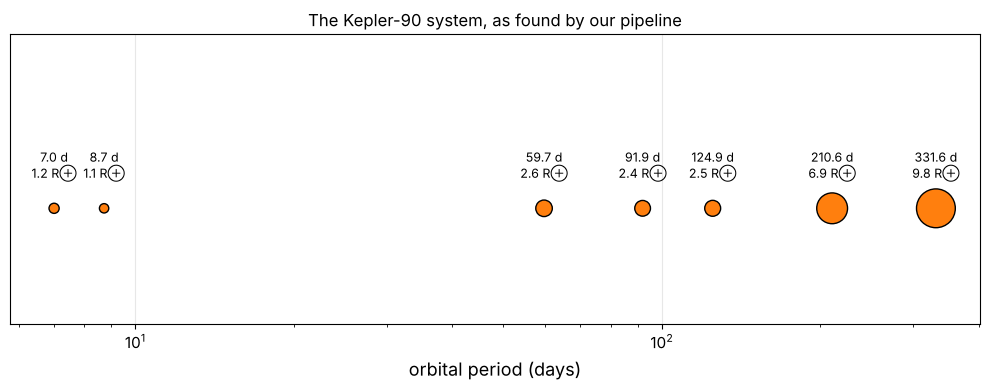

In [34]:
fig, ax = plt.subplots(figsize=(10, 4))
real = signals[signals["planet"]].sort_values("period")
ax.scatter(real["period"], np.zeros(len(real)), s=40 * real["radius_earth"] ** 1.3, c="tab:orange",
           edgecolor="k", zorder=3)
for _, r in real.iterrows():
    ax.annotate(f"{r['period']:.1f} d\n{r['radius_earth']:.1f} R⊕", (r["period"], 0), xytext=(0, 22),
                textcoords="offset points", ha="center", fontsize=9)
ax.set_xscale("log"); ax.set_yticks([]); ax.set_xlabel("orbital period (days)")
ax.set_ylim(-1, 1.5); ax.set_title("The Kepler-90 system, as found by our pipeline")
ax.grid(alpha=0.3, axis="x")
save_fig("kepler90_system_plot")
plt.show()

In [35]:
# Monitoring the model on the still-unlabeled CANDIDATES (the 'production' traffic)
cands = koi[koi["koi_disposition"] == "CANDIDATE"].copy()
cands["p_planet"] = final_model.predict_proba(cands[TRANSIT_FEATURES + STAR_FEATURES])[:, 1]
print(f"{len(cands)} candidates; {(cands['p_planet'] > thr[i95]).mean():.0%} pass the 95%-precision threshold")
cands.sort_values("p_planet", ascending=False)[["kepoi_name", "koi_period", "koi_prad", "koi_teq",
                                                 "p_planet"]].head(8).round(3)

1977 candidates; 15% pass the 95%-precision threshold


,kepoi_name,koi_period,koi_prad,koi_teq,p_planet
349,K00974.01,53.506,2.52,675.0,0.993
4424,K04526.01,30.539,2.72,669.0,0.989
1535,K01861.01,17.504,3.56,824.0,0.989
1496,K01856.01,46.299,4.33,592.0,0.988
3929,K02972.02,42.029,2.33,578.0,0.988
2847,K02972.01,13.251,1.98,850.0,0.987
1581,K01934.01,28.783,2.11,443.0,0.987
2403,K00268.01,110.378,3.02,473.0,0.987


In [36]:
# The fun part: small, temperate candidates the model believes in
hz = cands[(cands["koi_prad"] < 2) & cands["koi_teq"].between(180, 320) & (cands["p_planet"] > 0.5)]
hz.sort_values("p_planet", ascending=False)[["kepoi_name", "koi_period", "koi_prad", "koi_teq",
                                              "koi_insol", "p_planet"]].head(8).round(2)

,kepoi_name,koi_period,koi_prad,koi_teq,koi_insol,p_planet
2769,K03034.01,31.02,1.66,291.0,1.70,0.97
2408,K02862.01,24.58,1.64,316.0,2.35,0.96
1776,K02124.01,42.34,1.45,311.0,2.21,0.94
6543,K05652.01,91.51,1.43,302.0,1.97,0.93


In [37]:
import json
os.makedirs("animations", exist_ok=True)
sub = detrended.iloc[::4]
anim = {"planets": real[["period", "t0", "duration_h", "depth_ppm", "radius_earth"]].round(4).to_dict("records"),
        "lc": np.c_[sub["time"].round(4), ((sub["flux"] - 1) * 1e6).round(0)].tolist(),
        "srad": float(star["koi_srad"]), "noise_ppm": float(noise_ppm)}
with open(os.path.join("animations", "fitted_parameters.json"), "w") as f:
    json.dump(anim, f)
print(len(anim["planets"]), "planets,", len(anim["lc"]), "light-curve points exported")

7 planets, 11180 light-curve points exported
